# Project 3.6. Disorder in spatially extended systems

Given A a complex field, the complex Ginzburg-Lando (CGL) equation reads

$\boxed{\partial_tA=A+(1+i\alpha)\nabla^2A-(\beta-i)|A|^2A}$

The following figure shows the phase diagram of the two-dimensional CGL equation, found by Chaté and Manneville. Phase turbulence is observed between lines $L$ and $BF$, defect turbulence to the left of line $T$, and frozen states exist (approximately) to the fight of line $S_2$. Details are given in the text.

![Phase diagram of the two-dimensional CGL equation](../figures/Chaté-Manneville_Phase_Diagram.png)

In [20]:
# Common imports
%matplotlib inline
import time
from collections.abc import Callable

import numpy as np
import scipy.linalg as la
import scipy.sparse as sparse

import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.image import AxesImage
from IPython.display import HTML

from dataclasses import dataclass

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00", "#F0E442"]
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.5, 4.2),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#898781",
    "axes.linewidth": 0.9,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "axes.axisbelow": True,
    "animation.html": "jshtml",    # animations are rendered as interactive JavaScript widgets
    "animation.embed_limit": 60,   # in MB
})

# the random number generator
rng = np.random.default_rng(seed=2026)

# colormaps: sequential for u >= 0, diverging for signed fields, cyclic for phases
SEQ_CMAP = LinearSegmentedColormap.from_list("sequential", ["#f7f6f3", "#56B4E9", "#0072B2", "#0b2545"])
DIV_CMAP = LinearSegmentedColormap.from_list("diverging", ["#0072B2", "#f0efec", "#D55E00"])
PHASE_CMAP = "twilight"

# to draw a field u(x, t) as a space-time map
def show_spacetime(x: np.ndarray, t: np.ndarray, u: np.ndarray, ax: plt.Axes | None = None,
                   cmap=SEQ_CMAP, label: str | None = None, **kwargs) -> AxesImage:
    """Draw u[n, j] = u(x_j, t_n) as a map, with x horizontal and t increasing upwards."""
    ax = ax if ax is not None else plt.gca()
    image = ax.imshow(u, origin="lower", aspect="auto", cmap=cmap,
                      extent=(x[0], x[-1], t[0], t[-1]), **kwargs)
    ax.set(xlabel="$x$", ylabel="$t$")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.figure.colorbar(image, ax=ax, label=label, pad=0.02)
    return image

## Part 1: Extension of project 3 in 2D

### Fourrier Transform Solver

1.1. We write a `Gaussian2D` class for the Gaussian $u_0(x)=U_0\exp(-((x-x_0)^2+(y-y_0)^2)/\sigma^2)$

In [21]:
@dataclass
class Gaussian2D:
    """A 2D Gaussian pulse of given width and amplitude, centered at (x0, y0)."""
    width: float
    amplitude: float
    x0: float
    y0: float

    def __call__(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        return self.amplitude * np.exp(-(((x - self.x0) / self.width) ** 2 + ((y - self.y0) / self.width) ** 2))

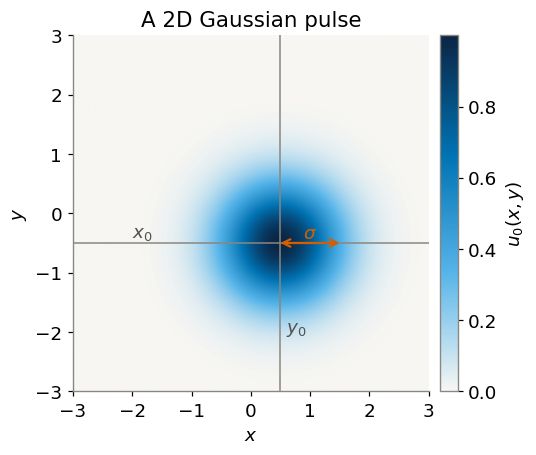

In [ ]:
# Plot of a 2D Gaussian pulse
gauss2d = Gaussian2D(width=1, amplitude=1, x0=0.5, y0=-0.5)
x = np.linspace(-3, 3, 400)
y = np.linspace(-3, 3, 400)
X, Y = np.meshgrid(x, y)
fig, ax = plt.subplots()
im = ax.imshow(gauss2d(X, Y), origin="lower", extent=(x[0], x[-1], y[0], y[-1]), cmap=SEQ_CMAP)
ax.set(xlabel="$x$", ylabel="$y$", title="A 2D Gaussian pulse")
ax.annotate("", xy=(gauss2d.x0 + gauss2d.width, gauss2d.y0), xytext=(gauss2d.x0, gauss2d.y0),
            arrowprops=dict(arrowstyle="<->", color=PALETTE[1], lw=1.5, shrinkA=0, shrinkB=0))
ax.text(gauss2d.x0 + gauss2d.width / 2, gauss2d.y0 + 0.08, r"$\sigma$", color=PALETTE[1], ha="center")
ax.axvline(gauss2d.x0, color="#898781", lw=1)
ax.axhline(gauss2d.y0, color="#898781", lw=1)
ax.text(-2, -0.4, "$x_0$", color="#52514e")
ax.text(0.6, -2, "$y_0$", color="#52514e")
ax.figure.colorbar(im, ax=ax, label="$u_0(x, y)$", pad=0.02)
plt.grid(False)
plt.show()

1.2. Time evolution for the advection-diffusion equation

We write a `Spectral2D` class and an `advance` function in order to advance the solution from $t$ to $t + T$ by steps of $dt$.

In [24]:
class Spectral2D:
    """Solve du/dt + V du/dx = D d^2u/dx^2 on the periodic box [0, L) x [0, L) with Fourier modes."""

    def __init__(self, L: float, n_points: int, D: float, V: float) -> None:
        self.L, self.D, self.V = L, D, V
        # x = L is the same point as x = 0, so it is not part of the grid
        # same thing for y = L
        self.x, self.dx = np.linspace(0, L, n_points, endpoint=False, retstep=True)
        self.y, self.dy = np.linspace(0, L, n_points, endpoint=False, retstep=True)
        self.kx = 2 * np.pi * np.fft.fftfreq(n_points, d=self.dx)
        self.ky = 2 * np.pi * np.fft.fftfreq(n_points, d=self.dy)
        self.u = np.zeros((n_points, n_points))
        self.t = 0.0

    def initialize(self, func: Callable[[np.ndarray, np.ndarray], np.ndarray]) -> None:
        """Set the initial condition u(x, y, 0) = func(x, y)."""
        X, Y = np.meshgrid(self.x, self.y)
        self.u = func(X, Y)
        self.t = 0.0

    def step(self, dt: float) -> None:
        """Advance the solution from t to t + dt."""
        u_hat = np.fft.fft2(self.u)
        kx2d, ky2d = np.meshgrid(self.kx, self.ky)
        u_hat *= np.exp(-(self.D * (kx2d**2 + ky2d**2) + 1j * self.V * kx2d) * dt)
        self.u = np.fft.ifft2(u_hat).real  # the imaginary part is only round-off noise
        self.t += dt

In [25]:
def advance(spectral: Spectral2D, T: float, n_steps: int) -> None:
    """Evolve the solution from t to t + T with n_steps steps of size T / n_steps."""
    dt = T / n_steps
    for _ in range(n_steps):
        spectral.step(dt)

1.3. Test on a simple case: Diffusion

We write the solution as a subclass of `Gaussian2D`

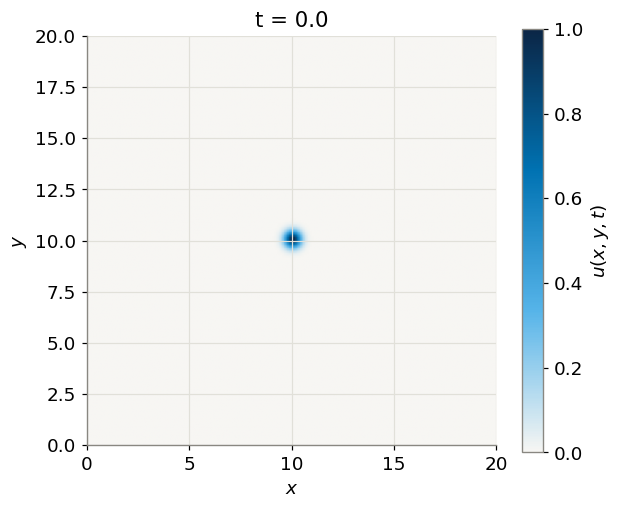

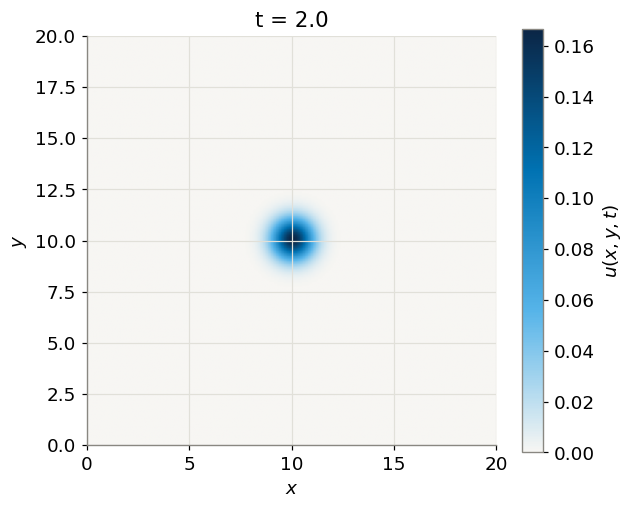

In [46]:
class DiffusingGaussian2D(Gaussian2D):
    """Exact solution of the diffusion equation on the infinite plane, for a Gaussian initial condition."""

    def __init__(self, width: float, amplitude: float, x0: float, y0: float, D: float) -> None:
        super().__init__(width, amplitude, x0, y0)
        self.D = D

    def __call__(self, x: np.ndarray, y: np.ndarray, t: float = 0.0) -> np.ndarray:
        width_t = np.sqrt(self.width**2 + 4 * self.D * t)
        return self.amplitude * (self.width / width_t)**2 * np.exp(-(((x - self.x0) / width_t) ** 2 + ((y - self.y0) / width_t) ** 2))

L, n_points, D = 20.0, 256, 0.1
exact2d = DiffusingGaussian2D(width=0.4, amplitude=1.0, x0=L / 2, y0=L / 2, D=D)
spectral2d = Spectral2D(L, n_points, D=D, V=0.0)
spectral2d.initialize(lambda x, y: exact2d(x, y, t=0.0))

# plot at different times:
times = [0.0, 2.0]
for t in times:
    advance(spectral2d, T=t, n_steps=100)
    plt.figure(figsize=(6, 5))
    im = plt.imshow(spectral2d.u, origin="lower", extent=(0, L, 0, L), cmap=SEQ_CMAP)
    plt.title(f"t = {spectral2d.t:.1f}")
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.colorbar(im, label="$u(x, y, t)$")
    plt.show()

1.4. Time evolution for the CGL equation

1.5. Test on a simple case: Benjamin-Feir

### Crank-Nicolson Solver

Test on a simple case: Benjamin-Feir